<a href="https://colab.research.google.com/github/Narmadha-H/MLA0202-FML/blob/main/ML13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Setup complete
   Year  Present_Price  Kms_Driven Fuel_Type Transmission  Owner  \
0  2006           7.99      104531    Diesel       Manual      0   
1  2018           9.42       81018    Diesel       Manual      0   
2  2016           7.58      149634    Petrol       Manual      0   
3  2012          13.04      116235    Diesel       Manual      0   
4  2012          17.71        4491    Petrol       Manual      0   

   Selling_Price  
0           1.00  
1           4.27  
2           2.31  
3           2.81  
4           4.61  
Linear Regression R2: 0.841
Random Forest R2    : 0.979


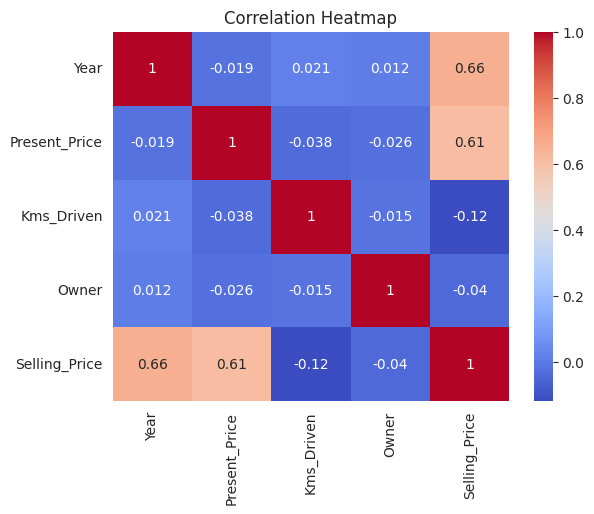

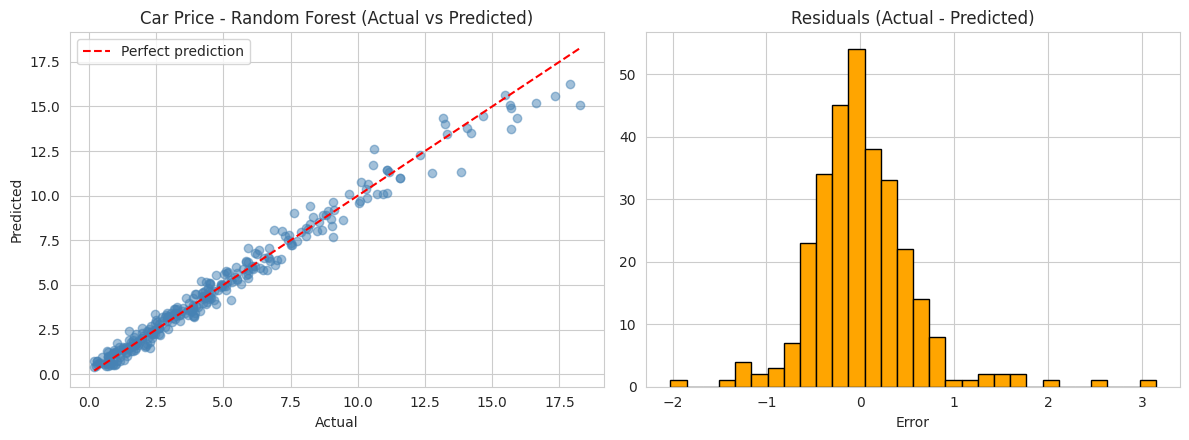

R2 = 0.979 | RMSE = 0.549 | MAE = 0.383


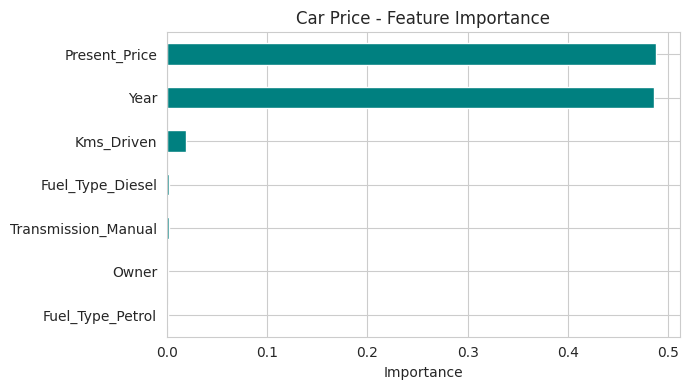

In [1]:
# ---------- Common imports and helper functions ----------
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")

from sklearn.datasets import load_iris, load_breast_cancer, fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression, Perceptron as SkPerceptron
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report, roc_curve, auc,
                             r2_score, mean_squared_error, mean_absolute_error,
                             precision_score, recall_score, f1_score)

sns.set_style("whitegrid")
rng = np.random.default_rng(42)

def plot_cm(y_true, y_pred, labels, title):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(title)
    plt.tight_layout(); plt.show()

def plot_reg(y_true, y_pred, title):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    ax[0].scatter(y_true, y_pred, alpha=0.5, color="steelblue")
    lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    ax[0].plot(lims, lims, "r--", label="Perfect prediction")
    ax[0].set_xlabel("Actual"); ax[0].set_ylabel("Predicted"); ax[0].set_title(title); ax[0].legend()
    ax[1].hist(y_true - y_pred, bins=30, color="orange", edgecolor="black")
    ax[1].set_title("Residuals (Actual - Predicted)"); ax[1].set_xlabel("Error")
    plt.tight_layout(); plt.show()
    print(f"R2 = {r2_score(y_true, y_pred):.3f} | RMSE = {np.sqrt(mean_squared_error(y_true, y_pred)):.3f} | MAE = {mean_absolute_error(y_true, y_pred):.3f}")

def plot_importance(names, values, title):
    s = pd.Series(values, index=names).sort_values()
    s.plot(kind="barh", figsize=(7, 4), color="teal"); plt.title(title); plt.xlabel("Importance")
    plt.tight_layout(); plt.show()

def plot_boundary(model, X2, y, xlabel, ylabel, class_names, title):
    # model must already be trained on the 2 features in X2
    x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
    y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    plt.figure(figsize=(6, 5))
    plt.contourf(xx, yy, Z, alpha=0.25, cmap="viridis")
    for i, c in enumerate(class_names):
        plt.scatter(X2[y == i, 0], X2[y == i, 1], label=c, edgecolor="k")
    plt.xlabel(xlabel); plt.ylabel(ylabel); plt.title(title); plt.legend(); plt.show()
print("Setup complete")

n = 1500
df = pd.DataFrame({
    "Year": rng.integers(2005, 2023, n),
    "Present_Price": rng.uniform(2, 25, n).round(2),
    "Kms_Driven": rng.integers(2000, 150000, n),
    "Fuel_Type": rng.choice(["Petrol", "Diesel", "CNG"], n, p=[.55, .4, .05]),
    "Transmission": rng.choice(["Manual", "Automatic"], n, p=[.8, .2]),
    "Owner": rng.choice([0, 1, 2], n, p=[.8, .15, .05]),
})
age = 2024 - df["Year"]
df["Selling_Price"] = (df["Present_Price"] * np.exp(-0.11 * age) * (1 - df["Kms_Driven"] / 600000)
                       * np.where(df["Fuel_Type"] == "Diesel", 1.1, 1.0)
                       * np.where(df["Transmission"] == "Automatic", 1.1, 1.0)
                       * (1 - 0.05 * df["Owner"]) + rng.normal(0, 0.3, n)).clip(0.2, None).round(2)
print(df.head())

X = pd.get_dummies(df.drop(columns="Selling_Price"), drop_first=True); y = df["Selling_Price"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

lr = LinearRegression().fit(X_tr, y_tr)
rf = RandomForestRegressor(n_estimators=200, random_state=42).fit(X_tr, y_tr)
print("Linear Regression R2:", round(r2_score(y_te, lr.predict(X_te)), 3))
print("Random Forest R2    :", round(r2_score(y_te, rf.predict(X_te)), 3))

sns.heatmap(df.select_dtypes("number").corr(), annot=True, cmap="coolwarm"); plt.title("Correlation Heatmap"); plt.show()
plot_reg(y_te, rf.predict(X_te), "Car Price - Random Forest (Actual vs Predicted)")
plot_importance(X.columns, rf.feature_importances_, "Car Price - Feature Importance")